# Residuals and identifiability in a two-cell gravity model

**Question:** For two vertically adjacent density cells and one surface line, does the weighted sensitivity matrix contain enough independent information to resolve both cell contrasts?

**Level 2 · Prerequisites: the preceding foundations lesson; estimated reading time: 50 minutes.**

## Objectives

Compute residuals and the weighted Jacobian for a two-cell model, then inspect singular directions and the limits of local identifiability.

## Setup

Use the repository's pinned Python 3.12 environment. Build it from the repository root with `scripts/setup.ps1 -Notebooks` on Windows or `scripts/setup.sh --notebooks` on Linux/macOS. This command is shown for reference; the notebook does not install packages.

```text
pip install simpeg==0.25.2 geoana==0.8.1 discretize==0.12.0
```

Import the product method and plotting tools once. The next cell reports the active implementation.

In [1]:
# Import repository methods and plotting tools for this lesson.
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / 'data-pipeline'))
import gravity_forward
print('Engine:', gravity_forward.ENGINE)


Engine: simpeg-0.25.2-geoana-0.8.1-f64-ram


## Data

This lesson builds a compact synthetic control in the notebook: two adjacent 100 m cells, 41 exterior stations, and an explicitly chosen 0.05 mGal standard deviation for each station. The standard deviation is an experimental assumption, not measured uncertainty. The product forward operator is `gravity_forward.forward_gravity`; the model response and Jacobian are evaluated anew in this kernel. No saved inversion output is read. The synthetic setup is original Apache-2.0 product material and carries no field-data claim.

Read the declared inputs or construct the authored synthetic geometry. No solver output is loaded.

In [2]:
# Define a two-layer synthetic prism column and exterior surface line.
mesh = {'origin_m': np.array([-50., -50., -300.]), 'hx_m': np.array([100.]),
        'hy_m': np.array([100.]), 'hz_m': np.array([100., 100.]),
        'active': np.array([True, True])}
x = np.linspace(-500., 500., 41)
receivers = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
base = {'schema': 'gravity-prism-forward-request-1',
        'frame': dict(gravity_forward.FRAME), 'mesh': mesh,
        'receivers_m': receivers, 'engine': gravity_forward.ENGINE}
print('Cells:', len(mesh['active']), '| stations:', len(receivers))


Cells: 2 | stations: 41


## Method

### Residuals have units and a sign

For observations d and prediction F(m), define r=d−F(m). A signed residual preserves whether the model underpredicts or overpredicts; RMSE removes the sign and retains mGal. In this synthetic exercise, observations are generated by the same declared forward model, then a deterministic alternating perturbation is added. This allows residual calculations to be followed without claiming a measured noise realization.

### Whitening states a noise assumption

With independent standard deviations σᵢ, the weighted residual is Wᵈr where Wᵈ=diag(1/σᵢ). The weighted least-squares term is ½‖Wᵈr‖². Whitening changes the relative influence of rows according to the declared uncertainty. It does not correct correlated errors, systematic bias, an incomplete regional model, or an incorrect covariance. Here a constant σ is an explicit teaching control.

### Sensitivity is local to a model and geometry

The product returns a Jacobian J with units mGal per kg/m³. Its columns are the data changes caused by unit density changes in each active cell. We form the whitened matrix WᵈJ and inspect singular values. Rank two would mean both columns are numerically independent under the chosen threshold; a small second singular value signals a poorly resolved direction. Numerical rank is threshold-dependent and is not geological resolution.

### A null direction changes the model little

The right singular vector associated with the smallest singular value describes a combination of cell contrasts that produces little weighted data change. Adding a modest multiple of that vector to a reference model provides a concrete pair of alternatives. The prediction difference, not visual similarity of a model drawing, tests whether this survey distinguishes the alternatives.

### Holdout and fit are different questions

A residual computed on the same synthetic line measures compatibility with those values only. A held-out line or spatial block tests transfer to locations not used for fitting; this lesson does not run an inverse or claim outer validation. The second plot reports sensitivity spectrum and alternative-model response change so readers see which evidence exists and which remains absent.

### What uncertainty does not include

The propagated covariance approximation Cₘ≈(JᵀCᵈ⁻¹J+βR)⁻¹ depends on the local linearization, chosen regularizer R, and β. It omits geometry uncertainty, model-selection uncertainty, structural error, and geological alternatives unless explicitly represented. This notebook reports no posterior probability and does not infer a confidence interval from a single noise assumption.

### Interpreting a small residual carefully

A low RMSE can coexist with a nearly rank-deficient sensitivity matrix: the data may be fit while a family of models remains plausible. Conversely, an identifiable two-parameter toy model does not imply a realistic Earth model is identifiable. Report residual units, sigma, matrix dimensions, rank threshold, and the model parameterization together so a reader can reproduce what “resolved” means here.

Call the actual forward method with a unit upper-cell contrast. Its Jacobian column is one sensitivity direction in this survey.

In [3]:
# Evaluate the product method for upper.
upper_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([0.0, 100.0])})
print('upper_result centre mGal:', float(upper_result['gz_up_mgal'][len(x) // 2]))

upper_result centre mGal: -0.02927236040238318


Repeat for the lower cell while preserving station order and geometry.

In [4]:
# Evaluate the product method for lower.
lower_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([100.0, 0.0])})
print('lower_result centre mGal:', float(lower_result['gz_up_mgal'][len(x) // 2]))

lower_result centre mGal: -0.010659464525418208


Compute the declared two-cell reference model from scratch; these predictions will define synthetic observations.

In [5]:
# Evaluate the product method for truth.
truth_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([40.0, 80.0])})
print('truth_result centre mGal:', float(truth_result['gz_up_mgal'][len(x) // 2]))

truth_result centre mGal: -0.027681674132073827


Evaluate a different model to test one finite non-uniqueness direction with the same operator.

In [6]:
# Evaluate the product method for alternative.
alternative_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([70.0, 65.0])})
print('alternative_result centre mGal:', float(alternative_result['gz_up_mgal'][len(x) // 2]))

alternative_result centre mGal: -0.026488659429341813


Run a second unit model. Its returned Jacobian provides an independent sensitivity matrix for consistency comparison.

In [7]:
# Evaluate the product method for unit.
unit_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([1.0, 1.0])})
print('unit_result centre mGal:', float(unit_result['gz_up_mgal'][len(x) // 2]))

unit_result centre mGal: -0.0003993182492780139


Form a reproducible noise realization and signed residual for a competing model. The sigma is an experimental assumption; it is not inferred from the solver.

In [8]:
# Generate deterministic synthetic observations and inspect weighted sensitivity.
sigma_mgal = 0.05
noise = 0.03 * np.where(np.arange(len(x)) % 2 == 0, 1.0, -1.0)
observed = truth_result['gz_up_mgal'] + noise
residual = observed - alternative_result['gz_up_mgal']
J = truth_result['jacobian_mgal_per_kg_m3']
weighted_J = J / sigma_mgal
u, singular_values, vh = np.linalg.svd(weighted_J, full_matrices=False)
rank = int(np.linalg.matrix_rank(weighted_J))
rmse = float(np.sqrt(np.mean(residual ** 2)))
print({'rmse_mgal': rmse, 'rank': rank, 'singular_values': singular_values.tolist()})

{'rmse_mgal': 0.03000835555409876, 'rank': 2, 'singular_values': [0.017207450046458773, 0.001803831511375517]}


The first panel compares the synthetic observations, the computed reference prediction, and the prediction after moving along the least-sensitive model direction. The second panel retains signed residuals in mGal. It shows how fit and model separation are related for this constructed example. It does not show a field residual map, an inversion result, or uncertainty beyond the stated alternating perturbation.

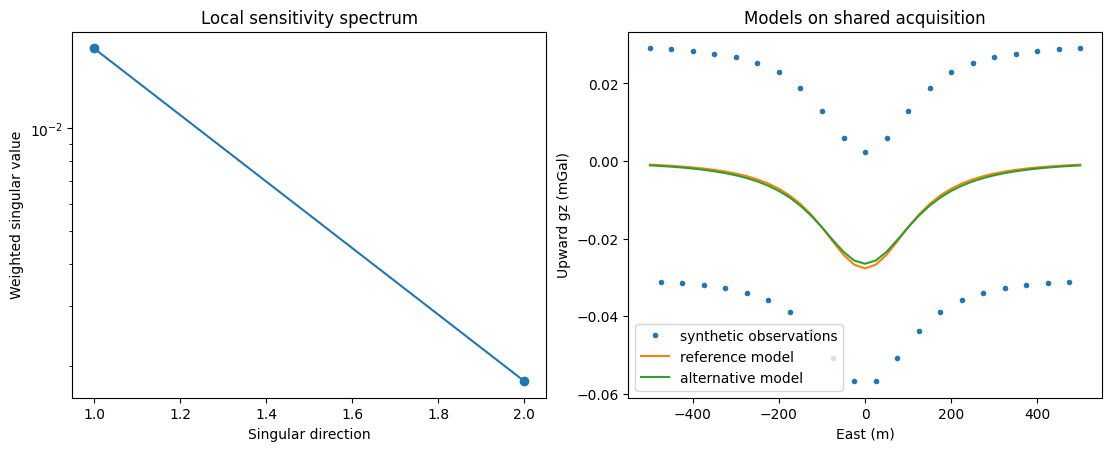

In [9]:
# Plot weighted singular values and competing predictions from real solver calls.
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
ax.semilogy(np.arange(1, len(singular_values) + 1), singular_values, 'o-')
ax.set(xlabel='Singular direction', ylabel='Weighted singular value', title='Local sensitivity spectrum')
bx.plot(x, observed, '.', label='synthetic observations')
bx.plot(x, truth_result['gz_up_mgal'], label='reference model')
bx.plot(x, alternative_result['gz_up_mgal'], label='alternative model')
bx.set(xlabel='East (m)', ylabel='Upward gz (mGal)', title='Models on shared acquisition')
bx.legend()
plt.show()

The singular-value panel uses the product Jacobian after division by the declared 0.05 mGal errors. The spectrum and reported numeric rank quantify local linear sensitivity for two cell parameters and this station line. The model-pair panel is a nonlinear forward check on the same direction. Neither establishes uniqueness outside this mesh, receiver geometry, or noise model.

Plot signed residuals against the declared one-sigma band. Coherent runs outside it would challenge independent, zero-mean error assumptions; this deterministic teaching perturbation is not an empirically calibrated threshold.

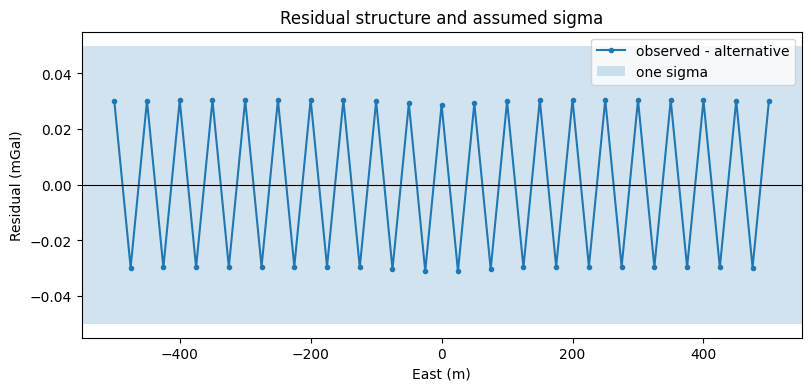

In [10]:
# Inspect residual sign against the declared independent-error scale.
fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
ax.plot(x, residual, marker='.', label='observed - alternative')
ax.axhspan(-sigma_mgal, sigma_mgal, alpha=0.2, label='one sigma')
ax.axhline(0.0, color='black', linewidth=0.8)
ax.set(xlabel='East (m)', ylabel='Residual (mGal)', title='Residual structure and assumed sigma')
ax.legend()
plt.show()

Each marker retains station identity and residual sign, while the band is the assumed standard deviation. The pattern can reveal systematic structure that one RMSE hides. Because noise was constructed deterministically, crossing this band does not have a probabilistic interpretation.

## Results

**Answer:** The weighted Jacobian rank is 2 and the alternative-model RMSE is 0.03000835555409876 mGal under the assumed 0.05 mGal sigma. Rank describes only this two-cell parameterization.

In [11]:
# Report rank, residual error and the explicit uncertainty scale.
print({'weighted_rank': rank, 'alternative_rmse_mgal': rmse,
       'noise_sd_mgal': sigma_mgal, 'jacobian_shape': J.shape})

{'weighted_rank': 2, 'alternative_rmse_mgal': 0.03000835555409876, 'noise_sd_mgal': 0.05, 'jacobian_shape': (41, 2)}


## Summary

Residuals describe prediction error under a stated convention; singular values describe local parameter sensitivity under a stated parameterization and weighting. Their combination can expose weakly resolved directions even when fit is small. This synthetic two-cell analysis is a diagnostic, not an accepted field inversion.

## References

- https://doi.org/10.1016/j.cageo.2015.09.015